### OICM Inference for models deployed with: vllm-omni
##### Qwen/Qwen-Image-Edit-2509 — image editing via OpenAI images.edits API
##### ref: https://platform.openai.com/docs/api-reference/images/createEdit

In [1]:
import os
import base64
import io
from pathlib import Path
from openai import OpenAI
from PIL import Image
from IPython.display import display

In [ ]:
api_key = os.getenv('OI_API_KEY')          # Your valid API key
deployment_id = os.getenv('OI_DEPLOYMENT_ID')  # Deployment ID for Qwen-Image-Edit-2509
base_url = f"https://inference.stg.openinnovation.ai/models/{deployment_id}/proxy/v1"  # replace "stg" with your environment
model_name = "Qwen/Qwen-Image-Edit-2509"   # change to your deployed model name

In [7]:
client = OpenAI(
    base_url=base_url,
    api_key=api_key
)

#### Helper utilities

In [8]:
def load_image_as_png_bytes(image_path: str) -> bytes:
    """Load an image from disk and return it as PNG bytes (required by the API)."""
    img = Image.open(image_path).convert("RGBA")
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def display_b64_image(b64_string: str):
    """Decode a base64 image string and display it inline."""
    image_bytes = base64.b64decode(b64_string)
    image = Image.open(io.BytesIO(image_bytes))
    display(image)
    return image

#### Load and preview the input image

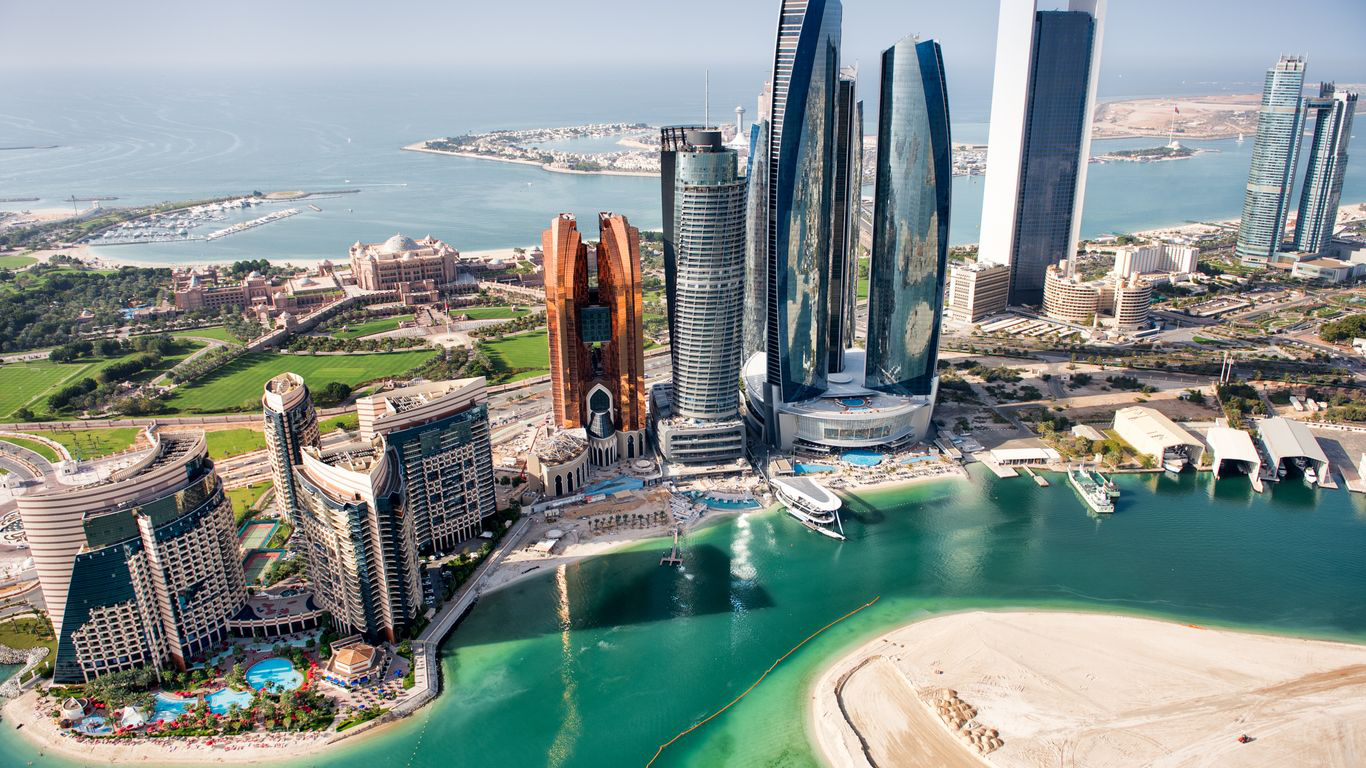

In [9]:
image_path = "./image-1.jpg"  # replace with your image path

display(Image.open(image_path))

#### Edit image (no mask — full-image instruction-based edit)

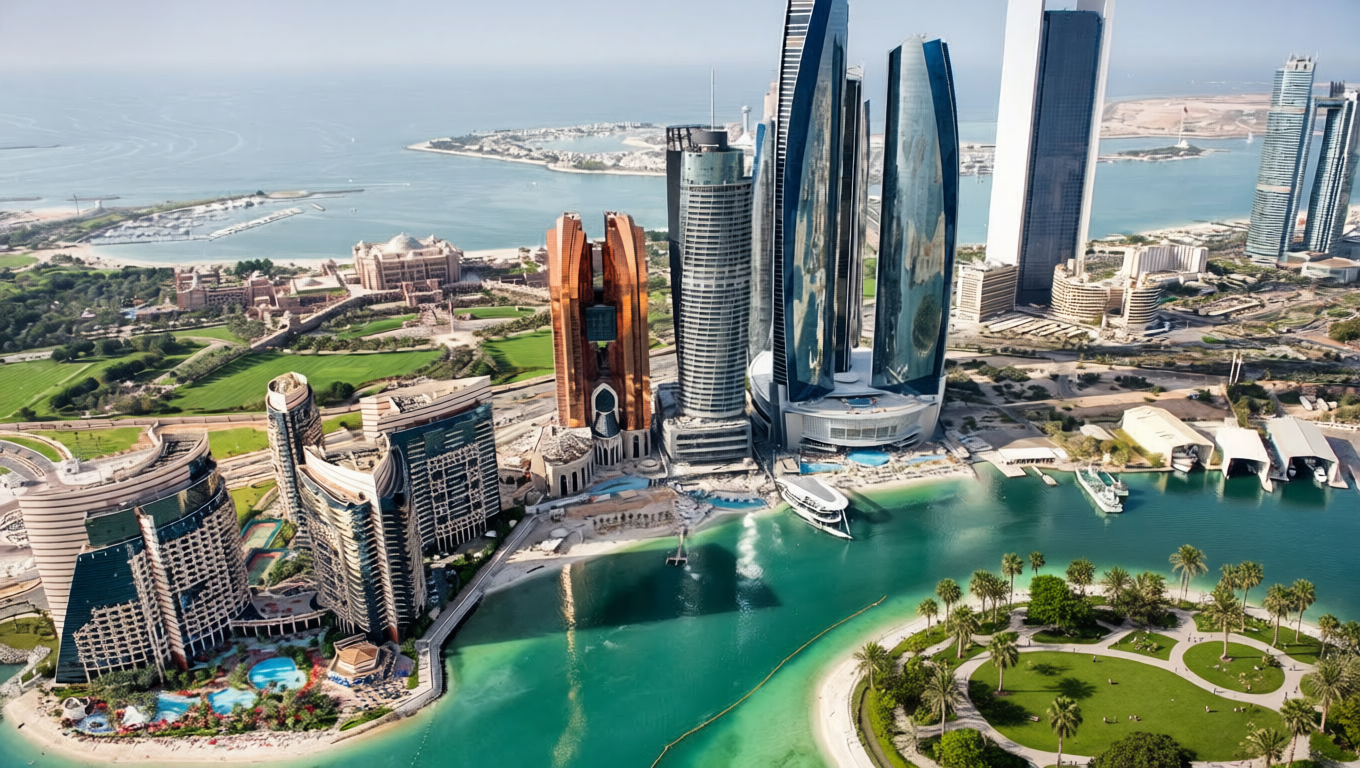

In [19]:
image_bytes = load_image_as_png_bytes(image_path)

response = client.images.edit(
    model=model_name,
    image=("image.png", image_bytes, "image/png"),
    prompt="Add a park in the bottom right corner",
    n=1,
    response_format="b64_json",
    extra_body={
        "negative_prompt": "blurry, low quality, distorted, deformed, ugly, bad anatomy, "
                           "poorly drawn, extra limbs, cloned face, disfigured, gross proportions, "
                           "malformed limbs, missing arms, missing legs, extra arms, extra legs, "
                           "fused fingers, too many fingers, long neck, unrealistic lighting, "
                           "watermark, text, signature, out of frame, cropped, draft"
    }
)
edited_image = display_b64_image(response.data[0].b64_json)